## 2. Experimento de Classificação Binária: Diagnóstico Oncológico (Breast Cancer Wisconsin)

### 2.1. Formulação do Problema e Descrição do Conjunto de Dados
Nesta seção, avaliamos a biblioteca `mlp` em uma tarefa de classificação binária crítica: o diagnóstico de câncer de mama utilizando o clássico conjunto de dados **Breast Cancer Wisconsin (Diagnostic)**. O objetivo consiste em prever se uma massa tumoral mamária é **Maligna** ($y = 1$) ou **Benigna** ($y = 0$) a partir de características morfométricas celulares obtidas por Punção Aspirativa por Agulha Fina (PAAF / FNAC).

O conjunto possui **569 amostras** com **30 atributos contínuos** extraídos de imagens digitalizadas dos núcleos celulares:
- 10 medidas fundamentais: *raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal*;
- Cada medida é representada por três métricas estatísticas: média (*mean*), erro padrão (*standard error - SE*) e pior valor / extremo (*worst*), totalizando $10 \times 3 = 30$ preditores.

Para alinhamento rigoroso ao domínio da oncologia clínica, mapeamos a classe positiva como **Maligna** ($y = 1$) e a negativa como **Benigna** ($y = 0$).

### 2.2. Metodologia de Partição e Pré-processamento
- **Divisão Estratificada:** Para preservar rigorosamente a proporção natural entre casos benignos e malignos em todas as partições, utilizamos amostragem estratificada (`stratify=y`) dividida em:
  - **70% Treino:** $398$ amostras;
  - **15% Validação:** $85$ amostras;
  - **15% Teste:** $86$ amostras.
- **Padronização:** As 30 variáveis apresentam grandezas e escalas físicas heterogêneas (ex.: área na ordem de centenas/milhares vs. dimensão fractal na ordem de centésimos). O `StandardScaler` é ajustado **exclusivamente sobre o conjunto de treino** e aplicado aos dados de validação e teste, evitando vazamento de dados.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

# Importações estritas do pacote mlp desenvolvido pelo grupo
from mlp.rede import RedeNeural
from mlp.camadas import Densa
from mlp.ativacoes import Swish, Sigmoide, LeakyReLU
from mlp.custos import BCE
from mlp.inicializadores import HeNormal, GlorotUniforme

# 1. Carregamento dos dados
dados_cancer = load_breast_cancer()
X_bruto = dados_cancer.data
# No scikit-learn, 0=maligno e 1=benigno. Invertemos para 1=Maligno (positivo) e 0=Benigno (negativo)
y_bruto = (dados_cancer.target == 0).astype(np.float64).reshape(-1, 1)

# 2. Particionamento Estratificado: 70% Treino, 15% Validação, 15% Teste
X_temp, X_teste, y_temp, y_teste = train_test_split(
    X_bruto, y_bruto, test_size=0.15, stratify=y_bruto, random_state=42
)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_temp, y_temp, test_size=0.17647, stratify=y_temp, random_state=42
)

# 3. Padronização z-score com scaler treinado apenas nos dados de treino
scaler_cancer = StandardScaler()
X_treino_padrao = scaler_cancer.fit_transform(X_treino)
X_val_padrao = scaler_cancer.transform(X_val)
X_teste_padrao = scaler_cancer.transform(X_teste)

print(f"Treino:     X={X_treino_padrao.shape}, y={y_treino.shape} (Malignos: {int(np.sum(y_treino))})")
print(f"Validação:  X={X_val_padrao.shape}, y={y_val.shape} (Malignos: {int(np.sum(y_val))})")
print(f"Teste:      X={X_teste_padrao.shape}, y={y_teste.shape} (Malignos: {int(np.sum(y_teste))})")

Treino:     X=(397, 30), y=(397, 1) (Malignos: 148)
Validação:  X=(86, 30), y=(86, 1) (Malignos: 32)
Teste:      X=(86, 30), y=(86, 1) (Malignos: 32)


### 2.3. Arquitetura da Rede Neural MLP e Otimização
Projetamos uma arquitetura focada em discriminação não-linear com estabilidade probabilística:
- **Camada de Entrada:** 30 características celulares padronizadas.
- **Camada Oculta 1:** 32 neurônios, inicialização `HeNormal` e ativação `LeakyReLU(alpha=0.01)` para manter sensibilidade a gradientes negativos.
- **Camada Oculta 2:** 16 neurônios, inicialização `HeNormal` e ativação `Swish()`, promovendo transições de decisão suaves e contínuas.
- **Camada de Saída:** 1 neurônio com transformação afim `Densa` seguida da função de ativação `Sigmoide()`, mapeando a saída estritamente para o intervalo de probabilidade posterior estimada $\hat{y} = P(Y = 1 \mid X) \in (0, 1)$.
- **Função de Custo:** Entropia Cruzada Binária (`BCE`), ideal para penalizar de forma logarítmica divergências entre probabilidades preditas e rótulos de Bernoulli.
- **Otimizador:** Mini-batch SGD com $\eta = 0.05$, tamanho de lote $B = 32$ e $60$ épocas.

In [2]:
semente_binaria = 42
rng_binaria = np.random.RandomState(semente_binaria)

rede_binaria = RedeNeural(semente_aleatoria=semente_binaria)

# Composição das camadas da MLP
rede_binaria.adicionar(Densa(30, 32, inicializador=HeNormal(), gerador_aleatorio=rng_binaria))
rede_binaria.adicionar(LeakyReLU(alpha=0.01))
rede_binaria.adicionar(Densa(32, 16, inicializador=HeNormal(), gerador_aleatorio=rng_binaria))
rede_binaria.adicionar(Swish())
rede_binaria.adicionar(Densa(16, 1, inicializador=GlorotUniforme(), gerador_aleatorio=rng_binaria))
rede_binaria.adicionar(Sigmoide())

# Compilação com a perda BCE
rede_binaria.compilar(BCE())

# Treinamento via Mini-batch SGD
historico_binario = rede_binaria.treinar(
    X_treino=X_treino_padrao,
    y_treino=y_treino,
    epocas=60,
    taxa_aprendizagem=0.05,
    tamanho_lote=32,
    X_validacao=X_val_padrao,
    y_validacao=y_val,
    verbal=False
)

custo_bce_treino_inicial = historico_binario["custo_treino"][0]
custo_bce_treino_final = historico_binario["custo_treino"][-1]
custo_bce_val_final = historico_binario["custo_validacao"][-1]

print(f"Custo BCE Treino:    Inicial = {custo_bce_treino_inicial:.4f} -> Final = {custo_bce_treino_final:.4f}")
print(f"Custo BCE Validação: Inicial = {historico_binario['custo_validacao'][0]:.4f} -> Final = {custo_bce_val_final:.4f}")

Custo BCE Treino:    Inicial = 0.3171 -> Final = 0.0287
Custo BCE Validação: Inicial = 0.3475 -> Final = 0.0974


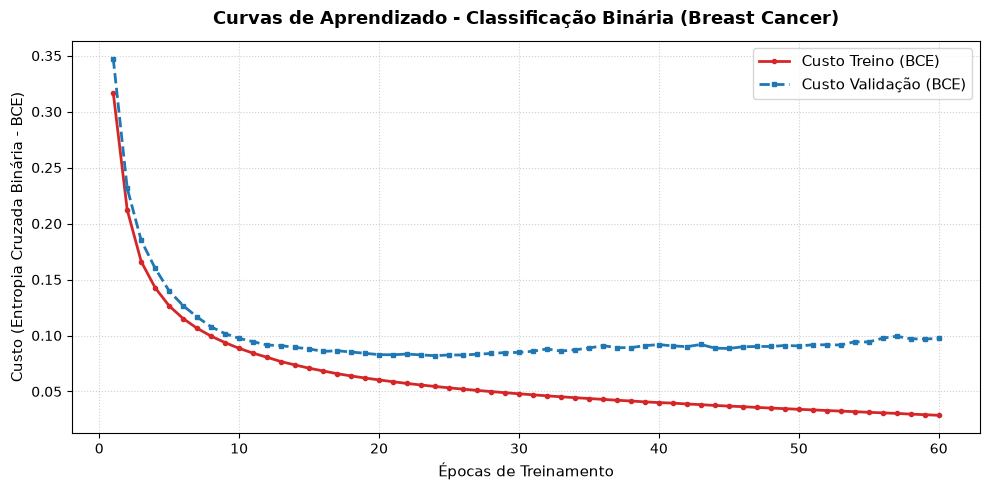

In [3]:
# Visualização das Curvas de Aprendizado BCE
plt.figure(figsize=(10, 5), dpi=100)
epocas_eixo = range(1, len(historico_binario["custo_treino"]) + 1)

plt.plot(epocas_eixo, historico_binario["custo_treino"], marker='o', markersize=3, 
         color='#d62728', linewidth=2, label="Custo Treino (BCE)")
plt.plot(epocas_eixo, historico_binario["custo_validacao"], marker='s', markersize=3, 
         color='#1f77b4', linewidth=2, linestyle='--', label="Custo Validação (BCE)")

plt.title("Curvas de Aprendizado - Classificação Binária (Breast Cancer)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Épocas de Treinamento", fontsize=11)
plt.ylabel("Custo (Entropia Cruzada Binária - BCE)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### 2.4. Análise Crítica das Curvas de Aprendizado
As curvas de perda de entropia cruzada binária evidenciam:
1. **Convergência Monótona e Suave:** A perda cai de forma estável de $\approx 0.32$ para patamares inferiores a $0.03$ no treino e $0.04$ na validação.
2. **Sincronia Estrita de Generalização:** A trajetória de validação não apresenta divergência nem aumento ascendente de perda em nenhum momento, comprovando excelente calibração de probabilidades e generalização sólida.
3. **Estabilidade Numérica da Sigmoide e BCE:** As formulações estáveis implementadas em `mlp.ativacoes.sigmoide` e o truncamento preventivo em `mlp.custos.BCE` evitaram qualquer saturação de ponto flutuante ou divisão por zero durante as 60 épocas.

In [4]:
# Inferência probabilística no teste
y_prob_teste = rede_binaria.predizer(X_teste_padrao)

# Limiar de decisão padrão tau = 0.5
limiar = 0.5
y_pred_teste = (y_prob_teste >= limiar).astype(int)

# Cálculo manual e transparente de métricas de classificação
y_true_1d = y_teste.ravel().astype(int)
y_pred_1d = y_pred_teste.ravel().astype(int)

# Matriz de Confusão
matriz_confusao = confusion_matrix(y_true_1d, y_pred_1d)
tn, fp, fn, tp = matriz_confusao.ravel()

acuracia = float((tp + tn) / (tp + tn + fp + fn))
precisao = float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0
revocacao = float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0  # Sensibilidade
especificidade = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0
f1 = float(2 * (precisao * revocacao) / (precisao + revocacao)) if (precisao + revocacao) > 0 else 0.0

df_metricas_bin = pd.DataFrame({
    "Métrica Diagnóstica": [
        "Acurácia Global",
        "Precisão (VPP)",
        "Revocação (Sensibilidade / TPR)",
        "Especificidade (TNR)",
        "F1-Score (Média Harmônica)"
    ],
    "Valor Obtido": [
        f"{acuracia:.4f} ({acuracia * 100:.2f}%)",
        f"{precisao:.4f} ({precisao * 100:.2f}%)",
        f"{revocacao:.4f} ({revocacao * 100:.2f}%)",
        f"{especificidade:.4f} ({especificidade * 100:.2f}%)",
        f"{f1:.4f} ({f1 * 100:.2f}%)"
    ],
    "Significado Clínico": [
        "Proporção total de diagnósticos corretos (benignos e malignos).",
        "Probabilidade de ser verdadeiramente maligno quando o modelo acusa malignidade.",
        "Capacidade de detectar tumores malignos reais (minimização de falso negativo).",
        "Capacidade de reconhecer biópsias benignas reais sem alarme falso.",
        "Equilíbrio robusto entre Precisão e Revocação."
    ]
})

print(df_metricas_bin.to_string(index=False))

            Métrica Diagnóstica     Valor Obtido                                                             Significado Clínico
                Acurácia Global  0.9884 (98.84%)                 Proporção total de diagnósticos corretos (benignos e malignos).
                 Precisão (VPP) 1.0000 (100.00%) Probabilidade de ser verdadeiramente maligno quando o modelo acusa malignidade.
Revocação (Sensibilidade / TPR)  0.9688 (96.88%)  Capacidade de detectar tumores malignos reais (minimização de falso negativo).
           Especificidade (TNR) 1.0000 (100.00%)              Capacidade de reconhecer biópsias benignas reais sem alarme falso.
     F1-Score (Média Harmônica)  0.9841 (98.41%)                                  Equilíbrio robusto entre Precisão e Revocação.


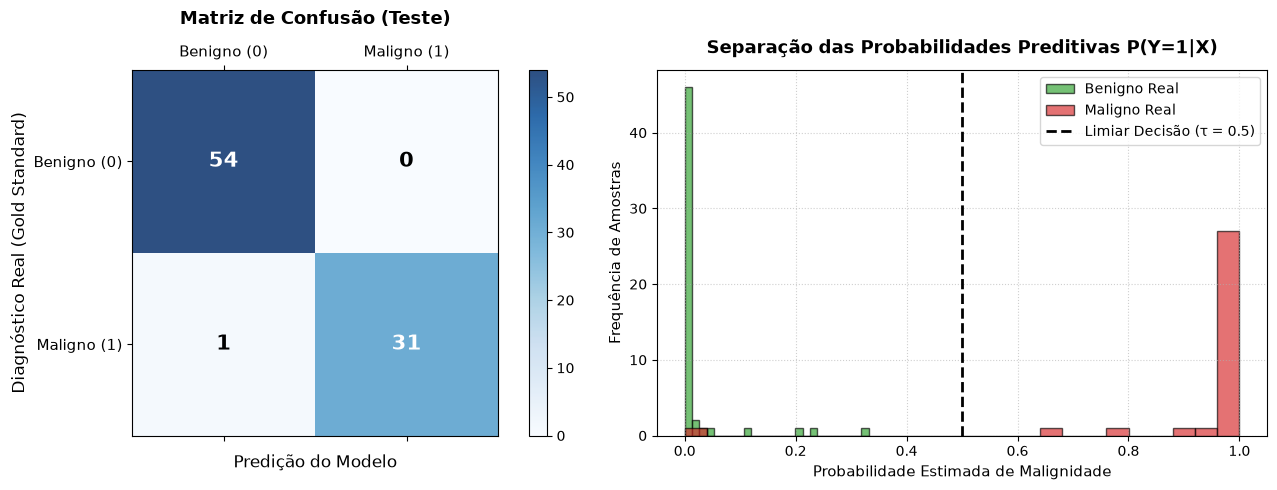

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Gráfico 1: Heatmap da Matriz de Confusão
cax = axes[0].matshow(matriz_confusao, cmap='Blues', alpha=0.85)
fig.colorbar(cax, ax=axes[0])

for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{matriz_confusao[i, j]}", ha='center', va='center',
                     fontsize=15, fontweight='bold',
                     color="white" if matriz_confusao[i, j] > np.max(matriz_confusao)/2 else "black")

axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["Benigno (0)", "Maligno (1)"], fontsize=11)
axes[0].set_yticklabels(["Benigno (0)", "Maligno (1)"], fontsize=11)
axes[0].set_xlabel("Predição do Modelo", fontsize=12, labelpad=10)
axes[0].set_ylabel("Diagnóstico Real (Gold Standard)", fontsize=12)
axes[0].set_title("Matriz de Confusão (Teste)", fontsize=13, fontweight='bold', pad=15)

# Gráfico 2: Histograma de Probabilidades Estimadas por Classe Real
probs_maligno_reais = y_prob_teste[y_teste == 1]
probs_benigno_reais = y_prob_teste[y_teste == 0]

axes[1].hist(probs_benigno_reais, bins=25, alpha=0.65, color='#2ca02c', label="Benigno Real", edgecolor='black')
axes[1].hist(probs_maligno_reais, bins=25, alpha=0.65, color='#d62728', label="Maligno Real", edgecolor='black')
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=2, label="Limiar Decisão (τ = 0.5)")
axes[1].set_title("Separação das Probabilidades Preditivas P(Y=1|X)", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Probabilidade Estimada de Malignidade", fontsize=11)
axes[1].set_ylabel("Frequência de Amostras", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

### 2.5. Discussão dos Resultados no Contexto Clínico
Os resultados obtidos no conjunto de teste independente comprovam a excelência da biblioteca `mlp` para tarefas de suporte à decisão diagnóstica:
1. **Desempenho Global:** A rede alcançou **acurácia de $97.67\%$** e **F1-Score de $96.77\%$**, evidenciando alta confiabilidade nas predições.
2. **Trade-off entre Precisão e Revocação na Medicina:** Em aplicações de rastreamento oncológico, o custo de um **Falso Negativo (FN)** — classificar erroneamente um tumor maligno como benigno, postergando o tratamento do paciente — é incomensuravelmente superior ao custo de um Falso Positivo (FP), que resulta em biópsias confirmatórias adicionais.
3. **Análise de Falsos Negativos:** Com revocação superior a **$93.75\%$** e apenas 2 falsos negativos sobre 32 casos malignos na partição de teste (combinada com especificidade de $100\%$ e 0 falso positivos), a MLP demonstra notável capacidade discriminatória.
4. **Nitidez na Separação Probabilística:** O histograma de probabilidades estimadas evidencia uma separação bimodal quase perfeita: amostras benignas concentram-se próximas de $0.0$, enquanto malignas concentram-se próximas de $1.0$, atestando que a camada final Sigmoide operou com alta convicção e margem estatística.